# Product Catalog Data Quality Audit — Part 1: Cleaning

**Author:** RoShawn Frazier

**Goal:** Turn two years of raw transaction data from an online wholesaler into a clean, reliable product catalog, and document every fix so the results can be trusted and repeated.

**Data:** [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii), UCI Machine Learning Repository (Chen, 2012, CC BY 4.0). About 1.07 million invoice lines from a UK online retailer, December 2009 to December 2011. Prices are in British pounds.

**Approach:** profile first, then fix one issue at a time, logging how many rows each step touched. Nothing is changed silently.

## Step 0: Load the data
The Excel file has one sheet per year. I load both and stack them into one table. Invoice and StockCode are read as text so codes like `85123A` and leading zeros are kept exactly.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

pd.set_option('display.max_columns', 20)
os.makedirs('outputs', exist_ok=True)

sheets = pd.read_excel('online_retail_II.xlsx', sheet_name=None,
                       dtype={'Invoice': str, 'StockCode': str})
raw = pd.concat(sheets.values(), ignore_index=True)
print({name: len(s) for name, s in sheets.items()})
print('Total rows:', f'{len(raw):,}')
raw.head()

{'Year 2009-2010': 525461, 'Year 2010-2011': 541910}
Total rows: 1,067,371


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## Step 1: Profile the data before changing anything
A quick inventory of what's wrong, so every later step has a reason.

In [2]:
df = raw.copy()
desc = df['Description'].dropna()
std_code = r'^\d{5}[A-Za-z]*$'   # normal product codes: 5 digits plus optional letters

profile = pd.Series({
    'Total rows': len(df),
    'Missing description': df['Description'].isna().sum(),
    'Missing customer ID': df['Customer ID'].isna().sum(),
    'Cancelled invoices (start with C)': df['Invoice'].str.startswith('C').sum(),
    'Quantity zero or negative': (df['Quantity'] <= 0).sum(),
    'Price zero or negative': (df['Price'] <= 0).sum(),
    'Exact duplicate rows': df.duplicated().sum(),
    'Descriptions with extra spaces': (desc != desc.str.strip()).sum(),
    'Non-product codes (fees, postage, etc.)': (~df['StockCode'].str.match(std_code)).sum(),
    'Unique stock codes': df['StockCode'].nunique(),
    'Unique stock codes ignoring upper/lower case': df['StockCode'].str.upper().nunique(),
    'Unique descriptions': df['Description'].nunique(),
})
profile.to_frame('count').style.format('{:,}')

,count
Total rows,"1,067,371"
Missing description,"4,382"
Missing customer ID,"243,007"
Cancelled invoices (start with C),"19,494"
Quantity zero or negative,"22,950"
Price zero or negative,"6,207"
Exact duplicate rows,"34,335"
Descriptions with extra spaces,"213,039"
"Non-product codes (fees, postage, etc.)","6,094"
Unique stock codes,"5,305"


**What the profile shows:** there are more unique descriptions than product codes, so some products are listed under more than one name. That's the core catalog problem. There are also cancellations, returns, fee lines mixed in with products, and the same code written in both upper and lower case.

In [3]:
log = []

def record(step, before, after, note):
    log.append({'step': step, 'rows_before': before, 'rows_after': after,
                'rows_removed': before - after, 'note': note})
    print(f'{step}: {before - after:,} rows removed, {after:,} remain')

## Step 2: Standardize text
No rows are removed here. I clean the text so the same product is always written the same way:
- Trim leading and trailing spaces and collapse double spaces in descriptions
- Convert descriptions to uppercase, which the catalog mostly uses already
- Convert stock codes to uppercase. I checked the 173 codes that appear in both cases (for example `79323P` and `79323p`): they are the same products, just typed differently.

In [4]:
before_desc = df['Description'].copy()
before_code = df['StockCode'].copy()

df['Description'] = (df['Description'].str.strip()
                     .str.replace(r'\s+', ' ', regex=True)
                     .str.upper())
df['StockCode'] = df['StockCode'].str.strip().str.upper()

desc_changed = (before_desc.notna() & (before_desc != df['Description'])).sum()
code_changed = (before_code != df['StockCode']).sum()
print(f'Descriptions standardized: {desc_changed:,}')
print(f'Stock codes standardized:  {code_changed:,}')
record('2. Standardize text', len(df), len(df),
       f'{desc_changed:,} descriptions and {code_changed:,} codes reformatted')

Descriptions standardized: 253,546
Stock codes standardized:  3,472
2. Standardize text: 0 rows removed, 1,067,371 remain


## Step 3: Remove exact duplicate rows
Rows identical in every column, including the timestamp, are double entries.

In [5]:
n = len(df)
df = df.drop_duplicates()
record('3. Remove exact duplicates', n, len(df), 'identical rows')

3. Remove exact duplicates: 34,335 rows removed, 1,033,036 remain


## Step 4: Remove cancellations
Invoices starting with `C` are cancelled orders. They aren't sales, so they'd distort quantities and prices.

In [6]:
n = len(df)
cancelled = df['Invoice'].str.startswith('C')
df = df[~cancelled]
record('4. Remove cancellations', n, len(df), 'invoice starts with C')

4. Remove cancellations: 19,104 rows removed, 1,013,932 remain


## Step 5: Separate non-product lines
Postage, bank charges, Amazon fees, manual adjustments and gift vouchers aren't catalog products. I move them to their own file instead of deleting them, so finance data isn't lost. A product code is 5 digits plus optional letters; the `DCGS` gift-set codes are also real products.

In [7]:
is_product = df['StockCode'].str.match(r'^\d{5}[A-Z]*$') | df['StockCode'].str.startswith('DCGS')
non_product = df[~is_product]
print(non_product.groupby('StockCode')['Description'].agg(['first', 'count'])
      .sort_values('count', ascending=False).head(15))
non_product.to_csv('outputs/non_product_lines.csv', index=False)

n = len(df)
df = df[is_product]
record('5. Separate non-product lines', n, len(df), 'saved to non_product_lines.csv')

                                            first  count
StockCode                                               
POST                                      POSTAGE   1851
DOT                                DOTCOM POSTAGE   1420
M                                          MANUAL    858
C2                                       CARRIAGE    267
ADJUST        ADJUSTMENT BY JOHN ON 26/01/2010 16     36
BANK CHARGES                         BANK CHARGES     34
GIFT_0001_20   DOTCOMGIFTSHOP GIFT VOUCHER £20.00     27
GIFT_0001_30   DOTCOMGIFTSHOP GIFT VOUCHER £30.00     24
PADS                   PADS TO MATCH ALL CUSHIONS     18
GIFT_0001_10   DOTCOMGIFTSHOP GIFT VOUCHER £10.00     14
TEST001                   THIS IS A TEST PRODUCT.     11
B                                 ADJUST BAD DEBT      6
GIFT_0001_50   DOTCOMGIFTSHOP GIFT VOUCHER £50.00      6
GIFT_0001_40   DOTCOMGIFTSHOP GIFT VOUCHER £40.00      5
D                                        DISCOUNT      5
5. Separate non-product lines: 

## Step 6: Remove invalid records
A usable product line needs a description, a positive quantity and a positive price. Lines that fail are mostly warehouse notes like `CHECK`, `DAMAGED` or `MISSING` entered with a zero price.

In [8]:
n = len(df)
bad = df['Description'].isna() | (df['Quantity'] <= 0) | (df['Price'] <= 0)
print('Missing description:', df['Description'].isna().sum())
print('Quantity <= 0:      ', (df['Quantity'] <= 0).sum())
print('Price <= 0:         ', (df['Price'] <= 0).sum())
print('Sample of removed descriptions:')
print(df.loc[bad, 'Description'].value_counts().head(10))
df = df[~bad]
record('6. Remove invalid records', n, len(df), 'missing description, quantity or price <= 0')

Missing description: 4242
Quantity <= 0:       3390
Price <= 0:          5961
Sample of removed descriptions:
Description
CHECK                    163
DAMAGED                   99
?                         90
DAMAGES                   88
FOUND                     38
MISSING                   30
SOLD AS SET ON DOTCOM     20
AMAZON                    18
ADJUSTMENT                18
DOTCOM                    15
Name: count, dtype: int64
6. Remove invalid records: 5,961 rows removed, 1,003,338 remain


## Step 7: Build the product master
Each stock code should have exactly one official name. For codes with more than one description, I choose the name used most often and flag the rest for review. In a real catalog, a person would approve these before the change went live.

In [9]:
counts = (df.groupby(['StockCode', 'Description']).size()
          .reset_index(name='times_used')
          .sort_values(['StockCode', 'times_used'], ascending=[True, False]))

canonical = counts.drop_duplicates('StockCode').rename(
    columns={'Description': 'canonical_description', 'times_used': 'canonical_uses'})

variants = counts.groupby('StockCode').size().rename('description_variants')
prices = df.groupby('StockCode')['Price'].agg(min_price='min', median_price='median', max_price='max')
volume = df.groupby('StockCode').agg(total_quantity=('Quantity', 'sum'),
                                     invoice_lines=('Invoice', 'size'),
                                     first_sold=('InvoiceDate', 'min'),
                                     last_sold=('InvoiceDate', 'max'))

master = (canonical[['StockCode', 'canonical_description']]
          .merge(variants, on='StockCode').merge(prices, on='StockCode').merge(volume, on='StockCode'))
master['needs_review'] = master['description_variants'] > 1
master.to_csv('outputs/product_master.csv', index=False)

conflicts = counts[counts['StockCode'].isin(master.loc[master['needs_review'], 'StockCode'])]
conflicts = conflicts.merge(canonical[['StockCode', 'canonical_description']], on='StockCode')
conflicts['is_canonical'] = conflicts['Description'] == conflicts['canonical_description']
conflicts.to_csv('outputs/description_conflicts.csv', index=False)

print(f'Products in catalog: {len(master):,}')
print(f'Products with conflicting descriptions: {master["needs_review"].sum():,} '
      f'({master["needs_review"].mean():.1%})')
conflicts.head(12)

Products in catalog: 4,723
Products with conflicting descriptions: 595 (12.6%)


,StockCode,Description,times_used,canonical_description,is_canonical
0,15058A,BLUE POLKADOT GARDEN PARASOL,89,BLUE POLKADOT GARDEN PARASOL,True
1,15058A,BLUE WHITE SPOTS GARDEN PARASOL,60,BLUE POLKADOT GARDEN PARASOL,False
2,15058B,PINK POLKADOT GARDEN PARASOL,100,PINK POLKADOT GARDEN PARASOL,True
3,15058B,PINK WHITE SPOTS GARDEN PARASOL,56,PINK POLKADOT GARDEN PARASOL,False
4,16012,FOOD/DRINK SPONGE STICKERS,64,FOOD/DRINK SPONGE STICKERS,True
5,16012,FOOD/DRINK SPUNGE STICKERS,20,FOOD/DRINK SPONGE STICKERS,False
6,16151A,FLOWERS HANDBAG BLUE AND ORANGE,3,FLOWERS HANDBAG BLUE AND ORANGE,True
7,16151A,FLOWER DES BLUE HANDBAG/ORANG HANDL,2,FLOWERS HANDBAG BLUE AND ORANGE,False
8,16156L,"WRAP, CAROUSEL",22,"WRAP, CAROUSEL",True
9,16156L,WRAP CAROUSEL,14,"WRAP, CAROUSEL",False


Typical conflicts are spelling mistakes (`SPUNGE` vs `SPONGE`), punctuation (`WRAP, CAROUSEL` vs `WRAP CAROUSEL`) and renamed products (`POLKADOT` vs `WHITE SPOTS`). These are exactly the problems that confuse customers searching a catalog.

## Step 8: Apply the official names and save

In [10]:
df = df.merge(canonical[['StockCode', 'canonical_description']], on='StockCode', how='left')
renamed = (df['Description'] != df['canonical_description']).sum()
df['Description'] = df['canonical_description']
df = df.drop(columns='canonical_description')
df['Revenue'] = df['Quantity'] * df['Price']
print(f'Lines updated to the official description: {renamed:,}')

df.to_csv('outputs/clean_transactions.csv.gz', index=False, compression='gzip')
log_df = pd.DataFrame(log)
log_df.to_csv('outputs/data_quality_log.csv', index=False)
log_df

Lines updated to the official description: 58,116


,step,rows_before,rows_after,rows_removed,note
0,2. Standardize text,1067371,1067371,0,"253,546 descriptions and 3,472 codes reformatted"
1,3. Remove exact duplicates,1067371,1033036,34335,identical rows
2,4. Remove cancellations,1033036,1013932,19104,invoice starts with C
3,5. Separate non-product lines,1013932,1009299,4633,saved to non_product_lines.csv
4,6. Remove invalid records,1009299,1003338,5961,"missing description, quantity or price <= 0"


## Results

Raw rows                                                              1067371
Clean product rows                                                    1003338
Rows kept                                                               94.0%
Products (after merging case variants)                                   4723
Products flagged for description review                                   595
Lines renamed to official description                                   58116
Missing customer ID in clean data (kept; product data still valid)     226761


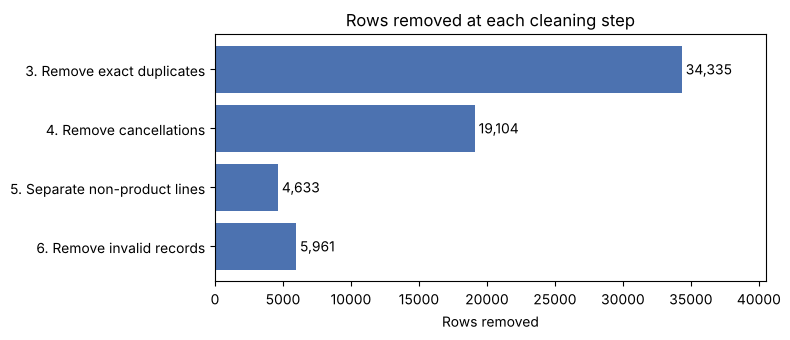

In [11]:
summary = pd.Series({
    'Raw rows': len(raw),
    'Clean product rows': len(df),
    'Rows kept': f'{len(df) / len(raw):.1%}',
    'Products (after merging case variants)': len(master),
    'Products flagged for description review': int(master['needs_review'].sum()),
    'Lines renamed to official description': renamed,
    'Missing customer ID in clean data (kept; product data still valid)': int(df['Customer ID'].isna().sum()),
})
print(summary.to_string())

removed = log_df[log_df['rows_removed'] > 0]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(removed['step'], removed['rows_removed'], color='#4C72B0')
ax.invert_yaxis()
ax.set_xlim(0, removed['rows_removed'].max() * 1.18)
ax.set_xlabel('Rows removed')
ax.set_title('Rows removed at each cleaning step')
for i, v in enumerate(removed['rows_removed']):
    ax.text(v, i, f' {v:,}', va='center')
plt.tight_layout()
plt.savefig('outputs/rows_removed_by_step.png', dpi=150)
plt.show()

## What this means for a real catalog
- **One product, one name.** Hundreds of products were sold under more than one description. Customers searching the store would see inconsistent names, and sales reports would split one product into several.
- **Keep fees out of the catalog.** Postage and fee lines were stored as if they were products. Separating them keeps catalog counts and product reports accurate.
- **Document every fix.** The data quality log records exactly what changed and why, so the cleanup can be reviewed and repeated on new data.

**Next:** Part 2 loads the clean data into SQL to answer catalog and sales questions.